# 2. Honest evaluation: how good is the model, really?

The original notebook reported 81% accuracy. This notebook checks that number, replaces the evaluation with one that can be trusted, and compares six models on equal terms.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 2.1 Reproduce the original result

**What we're looking for.** The original recipe, run exactly as written, to confirm we start from the same place.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from src.data import load_raw

d = load_raw().astype(float)
d["Glucose"] = d["Glucose"].replace(0, d["Glucose"].mean())   # filled using the WHOLE table
d["BMI"] = d["BMI"].replace(0, d["BMI"].median())
X4, y_raw = d[["Pregnancies", "Glucose", "BMI", "Age"]], d["Outcome"].astype(int)

X_tr, X_te, y_tr, y_te = train_test_split(X4, y_raw, test_size=0.2, random_state=0)
original = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
print(f"Accuracy on the test set: {original.score(X_te, y_te):.1%}  ({len(y_te)} women)")

Accuracy on the test set: 80.5%  (154 women)


**How to read it.** One model, trained on 80% of the women and scored on the other 20% (154 women).

**What it means.** The 81% reproduces. But it rests on one particular random split, and 154 women is a small test set. One or two lucky rows move the score by a point.

**What's next and why.** Repeat the same recipe with different random splits to see how much the score depends on luck.

## 2.2 The same recipe on 200 different splits

**What we're looking for.** The spread of scores when nothing changes except which women land in the test set.

Original split: 80.5%
Average of 200: 76.7%   lowest 68.2%   highest 83.8%
Splits that scored below the original: 88%


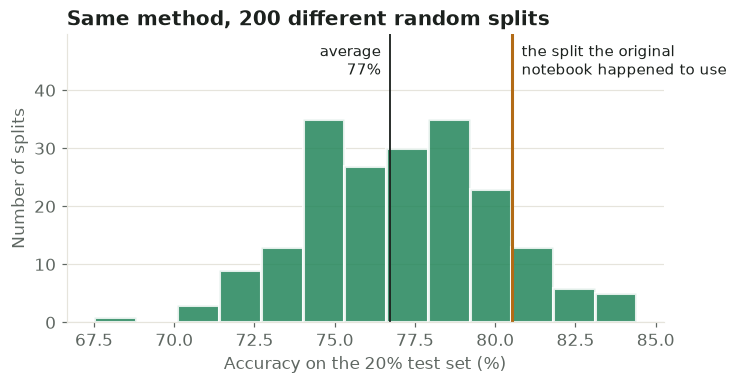

In [3]:
from src.evaluate import lucky_split_demo
from src import figures
ls = lucky_split_demo()
print(f"Original split: {ls['original_seed_accuracy']:.1%}")
print(f"Average of 200: {ls['mean']:.1%}   lowest {ls['min']:.1%}   highest {ls['max']:.1%}")
print(f"Splits that scored below the original: {ls['share_below_original']:.0%}")
figures.lucky_split();

**How to read it.** Each bar counts how many of the 200 splits landed at that accuracy. The black line is the average. The orange line is the split the original notebook used.

**What it means.** The same method scores anywhere from 68% to 84%, and averages 77%. The original split beat 88% of the others. The 81% was a fortunate draw. The honest figure for that recipe is about 77%, against a do-nothing floor of 65%.

**What's next and why.** Replace the single split with repeated cross-validation, which averages over many splits by design, and fix the leak in how the gaps were filled.

## 2.3 A leak-free pipeline, scored by repeated cross-validation

**What we're looking for.** A trustworthy score for logistic regression using all eight measurements.

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.data import load_data

X, y = load_data()                      # zeros are now proper missing values

pipe = make_pipeline(
    SimpleImputer(strategy="median"),   # fill gaps with the TRAINING fold's median
    StandardScaler(),                   # put every measurement on the same scale
    LogisticRegression(max_iter=1000),
)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)   # 50 train/test splits
res = cross_validate(pipe, X, y, cv=cv, scoring=["roc_auc", "accuracy", "recall"])
for k in ["roc_auc", "accuracy", "recall"]:
    v = res[f"test_{k}"]
    print(f"{k:9s} mean {v.mean():.3f}   spread (sd) {v.std():.3f}")

roc_auc   mean 0.835   spread (sd) 0.027
accuracy  mean 0.767   spread (sd) 0.029
recall    mean 0.558   spread (sd) 0.067


**How to read it.** Cross-validation cuts the data into 5 parts, trains on 4 and tests on the 5th, and rotates so every woman is tested once. Doing that 10 times with different cuts gives 50 scores. `mean` is their average and `sd` is how much they wobble. `roc_auc` (AUC) is the chance the model gives a higher risk to a woman with diabetes than to one without: 0.5 is a coin flip, 1.0 is perfect. `recall` is the share of true cases caught, also called sensitivity.

**What it means.** AUC is 0.835, accuracy 77%, and recall 56%. The pipeline matters because the fill-in values and the rescaling are re-learned inside each training fold, so nothing about the test women leaks in. The recall is the uncomfortable number: at the standard setting the model misses 44% of the women who have diabetes.

**What's next and why.** See whether a more complex model does better, scored on exactly the same 50 splits.

## 2.4 Six models on equal terms

**What we're looking for.** Whether tree-based models beat plain logistic regression, and how far any of them is from two simple yardsticks: doing nothing, and using glucose alone.

,auc,auc_sd,avg_precision,brier,accuracy,sensitivity
model,,,,,,
Random forest,0.838,0.025,0.720,0.156,0.763,0.582
Logistic regression,0.835,0.027,0.722,0.157,0.767,0.558
Gradient boosting,0.823,0.028,0.698,0.164,0.755,0.601
Decision tree,0.807,0.035,0.656,0.169,0.742,0.642
Glucose only (logistic),0.791,0.033,0.683,0.172,0.745,0.491
Always predict 'no diabetes',0.500,0.000,0.349,0.227,0.651,0.000


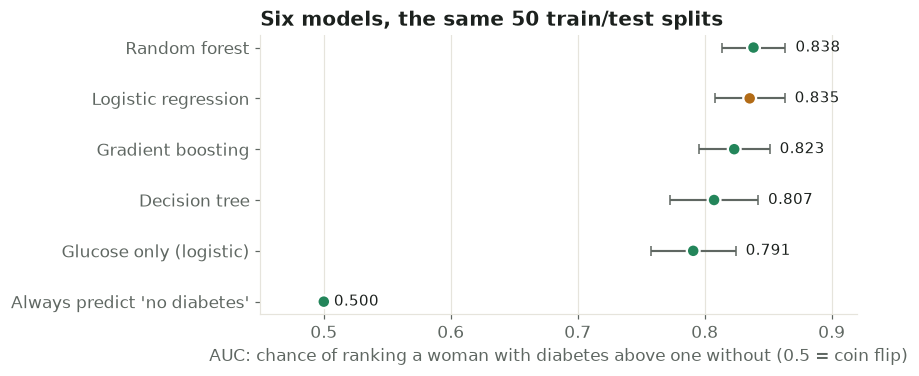

In [5]:
from src.evaluate import compare_models
from src import figures
table = compare_models(X, y)
display(table[["auc", "auc_sd", "avg_precision", "brier", "accuracy", "sensitivity"]].sort_values("auc", ascending=False))
figures.model_comparison();

**How to read it.** Each row is a model. `auc` is explained above and `auc_sd` is its wobble across the 50 splits. `brier` measures how far the predicted probabilities are from what happened (lower is better). In the chart, each dot is the average AUC and the whisker is one standard deviation either side.

**What it means.** Random forest (0.838) and logistic regression (0.835) are tied: the gap is a tenth of the wobble between splits. Gradient boosting (0.823) and a single decision tree (0.807) are behind. Glucose alone reaches 0.791, so the other seven measurements together add about 0.04. With 768 rows and eight inputs there isn't enough data for a complex model to find patterns a straight-line model misses.

**What's next and why.** Logistic regression goes forward for Milestone 1: it ties for best, its probabilities are easy to explain, and it can run inside a web page. Milestone 4 gives the complex models a fair second chance with tuning and nested cross-validation (E12).

## 2.5 Did dropping four columns matter?

**What we're looking for.** The original notebook dropped blood pressure, skinfold, insulin and family history because their correlation with the outcome looked low. Does a four-input model lose anything?

In [6]:
four = ["Pregnancies", "Glucose", "BMI", "Age"]
res4 = cross_validate(pipe, X[four], y, cv=cv, scoring=["roc_auc"])
print(f"All eight inputs: AUC {res['test_roc_auc'].mean():.3f}")
print(f"Four inputs:      AUC {res4['test_roc_auc'].mean():.3f}")

All eight inputs: AUC 0.835
Four inputs:      AUC 0.833


**How to read it.** Two versions of the same model, scored on the same 50 splits.

**What it means.** 0.835 against 0.833. The four dropped columns add almost nothing in a straight-line model, so the original instinct was reasonable, even though picking columns by looking at the whole table is itself a small leak. All eight stay in for now so the app can show each one's contribution.

**What's next and why.** Notebook 3 takes the chosen model and asks the practical questions: where to set the cut-off, whether the probabilities can be believed, and who it works less well for.